# UR5 110-episode π0.5 training — A100 Colab

Fine-tune **`lerobot/pi05_base`** on **110 episodes / 285,204 frames at 20 Hz** from `ur5_cube_110ep_v3`. This is a separate Pi0.5 experiment, initialized from its base model. Inputs are base/wrist RGB, seven-dimensional state, and the task instruction. Targets remain six absolute joint positions in radians plus the absolute binary gripper command (0 closed, 1 open).

Use a **fresh A100 40 GB or larger runtime**, with Python 3.12 or 3.13. Run cells top to bottom. The default **expert** profile freezes the vision-language backbone and trains the action expert/projections using bfloat16 and gradient checkpointing. An actual optimizer-step probe selects a batch that fits; fitting is not guaranteed until this probe passes. Full fine-tuning can be selected in configuration but needs more memory.

The starting budget is **20,000 optimizer steps**, with checkpoints every **2,500**, following the previous Pi0 experiment. The notebook reports the resulting number of dataset passes and estimates training time after the batch probe. This is not matched to the SmolVLA notebook's eight-pass budget and does not constitute a controlled model comparison. You can edit the step budget before training.

The dataset is already in Drive under `MyDrive/VLA_Thesis/Sorted VLA Backup Final/pHYSICAL UR5/datasets/lerobot/ur5_cube_110ep_v3/`. The notebook accepts that folder or a tar/checksum pair. It preserves its quantile statistics, checks every state/action row, and decodes 330 paired camera samples. All episodes are training data; no held-out evaluation is enabled. The retained original four-transition episode is unchanged.

Before running: accept the [PaliGemma tokenizer license](https://huggingface.co/google/paligemma-3b-pt-224) and create a [Hugging Face read token](https://huggingface.co/settings/tokens). Add it to **Colab Secrets → HF_TOKEN** with notebook access, or enter it in the authentication cell's hidden prompt. An existing Hugging Face login is also accepted. W&B is optional. Keep sufficient Drive capacity for eight large checkpoints plus final exports (many tens of GB). Local staging requires at least 60 GiB free; only the latest two verified local checkpoints are retained. Drive retains all completed checkpoints for this run.

References: [LeRobot Pi0.5 training](https://huggingface.co/docs/lerobot/main/en/pi05), [base model](https://huggingface.co/lerobot/pi05_base), [pinned LeRobot 0.6.1](https://pypi.org/project/lerobot/0.6.1/), [TorchCodec compatibility](https://github.com/meta-pytorch/torchcodec#compatibility-with-torch-versions).


In [1]:
# 1. Verify the assigned runtime before importing torch.
import json, os, platform, subprocess, sys, time
from pathlib import Path

def output(command):
    return subprocess.run(command, text=True, capture_output=True, check=False).stdout.strip()

gpu_report = output(["nvidia-smi", "--query-gpu=name,memory.total,driver_version", "--format=csv,noheader,nounits"])
print(gpu_report)
assert gpu_report, "No NVIDIA GPU assigned"
gpu_name, memory_mib, driver = [item.strip() for item in gpu_report.split(",", 2)]
assert "A100" in gpu_name, f"Expected an A100 runtime, received {gpu_name}"
assert int(memory_mib) >= 38000, f"Expected the 40 GB A100, received {memory_mib} MiB"
assert 'torch' not in sys.modules and 'torchvision' not in sys.modules, 'Start a fresh runtime before installing the pinned stack.'
runtime_report = {"python": sys.version, "platform": platform.platform(), "gpu": gpu_name, "memory_mib": int(memory_mib), "driver": driver}
print(json.dumps(runtime_report, indent=2))
assert (3, 12) <= sys.version_info[:2] <= (3, 13), 'This pinned stack expects Python 3.12 or 3.13.'


NVIDIA A100-SXM4-40GB, 40960, 580.82.07
{
  "python": "3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]",
  "platform": "Linux-6.6.122+-x86_64-with-glibc2.39",
  "gpu": "NVIDIA A100-SXM4-40GB",
  "memory_mib": 40960,
  "driver": "580.82.07"
}


In [2]:
# 2. Mount Drive and configure the new dataset.
from google.colab import drive
drive.mount('/content/drive')
DRIVE_ROOT = Path('/content/drive/MyDrive/VLA_Thesis/Sorted VLA Backup Final/pHYSICAL UR5')
DATASET_NAME = 'ur5_cube_110ep_v3'
REPO_ID = f'local/{DATASET_NAME}'
EXPECTED_EPISODES = 110
EXPECTED_FRAMES = 285204
TASK = 'Pick up the orange cube and place it in the bowl'
TRAIN_STEPS = 20_000
SAVE_FREQ = 2_500
FINETUNE_MODE = 'expert'  # 'expert' or 'full'
LOCAL_CHECKPOINTS_TO_KEEP = 2
USE_WANDB = True
RUN_TAG = time.strftime('%Y%m%d_%H%M%S')
DATASET_DRIVE_FOLDER = DRIVE_ROOT / 'datasets/lerobot' / DATASET_NAME
DATASET_ARCHIVE = DRIVE_ROOT / 'datasets/lerobot' / f'{DATASET_NAME}.tar'
DATASET_CHECKSUM = Path(f'{DATASET_ARCHIVE}.sha256')
LOCAL_ARCHIVE = Path('/content') / DATASET_ARCHIVE.name
LOCAL_DATASET = Path('/content') / DATASET_NAME
CHECKPOINT_ROOT = DRIVE_ROOT / 'checkpoints/ur5_pi05_trained'
REPORT_ROOT = DRIVE_ROOT / 'reports/training'
DEPLOYMENT_ROOT = DRIVE_ROOT / 'deployment/downloaded_checkpoints'
assert DRIVE_ROOT.is_dir(), f'Drive root missing: {DRIVE_ROOT}'
folder_upload = DATASET_DRIVE_FOLDER.is_dir()
archive_upload = DATASET_ARCHIVE.is_file() and DATASET_CHECKSUM.is_file()
assert folder_upload or archive_upload, f'Upload {DATASET_DRIVE_FOLDER}, or {DATASET_ARCHIVE} plus its .sha256 file'
if folder_upload:
    for name in ('data', 'meta', 'videos'):
        assert (DATASET_DRIVE_FOLDER / name).is_dir(), f'Incomplete upload: missing {name}'
for directory in (CHECKPOINT_ROOT, REPORT_ROOT, DEPLOYMENT_ROOT):
    directory.mkdir(parents=True, exist_ok=True)
print('Input:', DATASET_DRIVE_FOLDER if folder_upload else DATASET_ARCHIVE)
print('Dataset:', EXPECTED_EPISODES, 'episodes;', EXPECTED_FRAMES, 'frames')
assert FINETUNE_MODE in {'expert', 'full'}
assert TRAIN_STEPS > 0 and SAVE_FREQ > 0
print('W&B:', USE_WANDB, '| Fine-tune mode:', FINETUNE_MODE, '| Steps:', TRAIN_STEPS)


Mounted at /content/drive
Input: /content/drive/MyDrive/VLA_Thesis/Sorted VLA Backup Final/pHYSICAL UR5/datasets/lerobot/ur5_cube_110ep_v3
Dataset: 110 episodes; 285204 frames
W&B: True | Fine-tune mode: expert | Steps: 20000


## Install the Pi0.5 training stack

Use a fresh runtime, separate from the SmolVLA runtime. This installs **LeRobot 0.6.1 with both `pi` and `training` extras**, Torch 2.7.1 / Torchvision 0.22.1, compatible TorchCodec 0.3.0, Transformers 5.4.0, and PyAV 15.1.0. Decoding explicitly uses PyAV. Version checks and model imports run before copying data or downloading weights. The exact resolved environment is saved with the run.


In [3]:
# Install before importing Torch or Transformers.
assert 'torch' not in sys.modules and 'transformers' not in sys.modules, 'Start a fresh runtime and run from the top.'
%pip install -q --upgrade pip
%pip install -q --index-url https://download.pytorch.org/whl/cu126 "torch==2.7.1" "torchvision==0.22.1" "torchaudio==2.7.1"
%pip install -q "lerobot[pi,training]==0.6.1" "torch==2.7.1" "torchvision==0.22.1" "torchcodec==0.3.0" "transformers==5.4.0" "av==15.1.0" matplotlib psutil
os.environ['PYTORCH_CUDA_ALLOC_CONF'] = 'expandable_segments:True'
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
import importlib.metadata as md, torch, torchvision, av
from lerobot.policies.pi05.configuration_pi05 import PI05Config
from lerobot.policies.pi05.modeling_pi05 import PI05Policy
assert torch.cuda.is_available() and torch.cuda.is_bf16_supported()
assert torch.__version__.startswith('2.7.1') and torchvision.__version__.startswith('0.22.1')
assert md.version('lerobot') == '0.6.1' and md.version('transformers') == '5.4.0'
assert av.__version__ == '15.1.0' and hasattr(av, 'option')
assert torchvision.extension._has_ops()
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
torch.set_float32_matmul_precision('high')
runtime_report.update({name: md.version(name) for name in ('torch', 'torchvision', 'lerobot', 'transformers', 'accelerate', 'av', 'torchcodec')})
runtime_report['cuda'] = torch.version.cuda
print(json.dumps(runtime_report, indent=2))


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 83.8 MB/s eta 0:00:00
{
  "python": "3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]",
  "platform": "Linux-6.6.122+-x86_64-with-glibc2.39",
  "gpu": "NVIDIA A100-SXM4-40GB",
  "memory_mib": 40960,
  "driver": "580.82.07",
  "torch": "2.7.1+cu126",
  "torchvision": "0.22.1+cu126",
  "lerobot": "0.6.1",
  "transformers": "5.4.0",
  "accelerate": "1.15.0",
  "av": "15.1.0",
  "torchcodec": "0.3.0",
  "cuda": "12.6"
}


In [4]:
# 3. Copy to local disk, verify every copied file, and retain a fingerprint report.
import hashlib, shutil, tarfile
from pathlib import PurePosixPath

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as stream:
        while chunk := stream.read(16 * 1024 * 1024):
            digest.update(chunk)
    return digest.hexdigest()

def tree_hashes(root):
    root = Path(root)
    return {str(p.relative_to(root)): sha256_file(p) for p in sorted(root.rglob('*')) if p.is_file()}

def copy_verified_tree(source, destination):
    source, destination = Path(source), Path(destination)
    before = tree_hashes(source)
    assert before, f'No files in {source}'
    if destination.exists():
        assert tree_hashes(destination) == before, f'Destination exists with different content: {destination}'
        return before
    staging = destination.with_name('.' + destination.name + '.copying')
    assert not staging.exists(), f'Partial copy exists: {staging}. Inspect it before retrying.'
    shutil.copytree(source, staging)
    assert tree_hashes(staging) == before, f'Copy checksum failed: {staging}'
    assert tree_hashes(source) == before, f'Source changed during copy: {source}'
    staging.rename(destination)
    return before

assert shutil.disk_usage('/content').free >= 60 * 1024**3, 'Need at least 60 GiB free local disk before staging/training.'
if folder_upload:
    print('Copying dataset folder; verifying SHA-256 of every file ...')
    dataset_file_hashes = copy_verified_tree(DATASET_DRIVE_FOLDER, LOCAL_DATASET)
else:
    expected_sha = DATASET_CHECKSUM.read_text().split()[0].lower()
    assert len(expected_sha) == 64 and all(c in '0123456789abcdef' for c in expected_sha)
    if not LOCAL_ARCHIVE.exists():
        shutil.copy2(DATASET_ARCHIVE, LOCAL_ARCHIVE)
    assert sha256_file(LOCAL_ARCHIVE) == expected_sha, 'Archive SHA-256 mismatch'
    assert not LOCAL_DATASET.exists(), f'Local dataset already exists: {LOCAL_DATASET}; inspect before extracting.'
    staging = Path('/content') / ('.' + DATASET_NAME + '.extracting')
    staging.mkdir(exist_ok=False)
    with tarfile.open(LOCAL_ARCHIVE, 'r:*') as archive:
        members = archive.getmembers()
        for member in members:
            relative = PurePosixPath(member.name)
            assert relative.parts and relative.parts[0] == DATASET_NAME, f'Unexpected archive root: {member.name}'
            assert not relative.is_absolute() and '..' not in relative.parts
            assert member.isfile() or member.isdir(), f'Unsupported archive entry: {member.name}'
        archive.extractall(staging, members=members, filter='data')
    (staging / DATASET_NAME).rename(LOCAL_DATASET)
    staging.rmdir()
    dataset_file_hashes = tree_hashes(LOCAL_DATASET)
EXPECTED_METADATA_SHA256 = {'meta/info.json': 'de71d93083204c98babf100c8331061badae2df7aa1a3bf23de5e8deecfa4fdf', 'meta/ur5_vla_conversion.json': 'eda8704603a39667c9b540b966cb8efdfee54e8b7d2ab4f34765ca24de592d21'}
for relative, expected in EXPECTED_METADATA_SHA256.items():
    assert sha256_file(LOCAL_DATASET / relative) == expected, f'Dataset metadata differs from the reviewed 110-episode artifact: {relative}'
for name in ('data', 'meta', 'videos'):
    assert (LOCAL_DATASET / name).is_dir(), f'Missing local {name}'
DATASET_HASH_REPORT = Path('/content') / f'{DATASET_NAME}_file_hashes.json'
DATASET_HASH_REPORT.write_text(json.dumps(dataset_file_hashes, indent=2))
print('COPY VERIFIED:', len(dataset_file_hashes), 'files;', LOCAL_DATASET)


Copying dataset folder; verifying SHA-256 of every file ...
COPY VERIFIED: 50 files; /content/ur5_cube_110ep_v3


Video validation: 10/110 episodes
Video validation: 20/110 episodes
Video validation: 30/110 episodes
Video validation: 40/110 episodes
Video validation: 50/110 episodes
Video validation: 60/110 episodes
Video validation: 70/110 episodes
Video validation: 80/110 episodes
Video validation: 90/110 episodes
Video validation: 100/110 episodes
Video validation: 110/110 episodes
{
  "episodes": 110,
  "frames": 285204,
  "fps": 20,
  "task": "Pick up the orange cube and place it in the bowl",
  "paired_video_samples": 330,
  "action_mode": "absolute",
  "validation": "PASS",
  "held_out_split": false
}


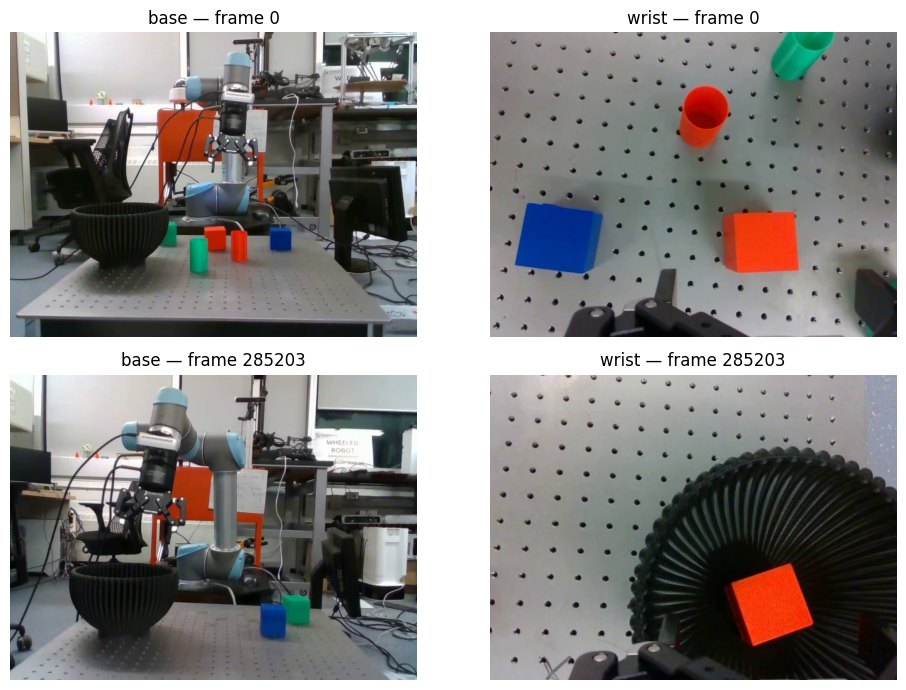

Pi0.5 quantile statistics verified


1270

In [5]:
# 4. Validate all state/action rows and decode three paired video samples per episode.
import numpy as np
from lerobot.datasets.lerobot_dataset import LeRobotDataset

dataset = LeRobotDataset(REPO_ID, root=LOCAL_DATASET, video_backend='pyav')
assert dataset.meta.total_episodes == EXPECTED_EPISODES
assert dataset.meta.total_frames == EXPECTED_FRAMES == len(dataset)
assert dataset.meta.fps == 20
assert list(dataset.meta.tasks.index) == [TASK]
features = dataset.meta.features
JOINT_ORDER = ['shoulder_pan_joint', 'shoulder_lift_joint', 'elbow_joint', 'wrist_1_joint', 'wrist_2_joint', 'wrist_3_joint']
for key in ('observation.images.base', 'observation.images.wrist'):
    assert features[key]['dtype'] == 'video' and tuple(features[key]['shape']) == (480, 640, 3)
assert tuple(features['observation.state']['shape']) == (7,)
assert tuple(features['action']['shape']) == (7,)
assert features['observation.state']['names'] == JOINT_ORDER + ['estimated_gripper_state']
assert features['action']['names'] == JOINT_ORDER + ['gripper_command']
conversion = json.loads((LOCAL_DATASET / 'meta/ur5_vla_conversion.json').read_text())
assert conversion['action_semantics'] == 'six absolute joint-position targets plus absolute binary gripper command'
assert conversion['action_mode'] == 'absolute' and conversion['joint_unit'] == 'radian'
assert conversion['joint_order'] == JOINT_ORDER
assert conversion['gripper_closed_value'] == 0.0 and conversion['gripper_open_value'] == 1.0
assert conversion['gripper_is_measured'] is False
assert len(conversion['source_episode_names']) == len(set(conversion['source_episode_names'])) == EXPECTED_EPISODES
assert not {'episode_20261001_175654', 'episode_20261001_182413'} & set(conversion['source_episode_names'])

rows_checked, episode_ids = 0, set()
vectors = dataset.hf_dataset.select_columns(['observation.state', 'action', 'episode_index', 'task_index'])
for batch in vectors.iter(batch_size=8192):
    state = np.asarray(batch['observation.state'], dtype=np.float32)
    action = np.asarray(batch['action'], dtype=np.float32)
    assert state.ndim == 2 and state.shape == action.shape and state.shape[1] == 7
    assert np.isfinite(state).all() and np.isfinite(action).all()
    for gripper in (state[:, 6], action[:, 6]):
        assert np.all(np.minimum(np.abs(gripper), np.abs(gripper - 1)) < 1e-5)
    assert np.all(np.asarray(batch['task_index']) == 0)
    episode_ids.update(np.asarray(batch['episode_index']).reshape(-1).tolist())
    rows_checked += len(state)
assert rows_checked == EXPECTED_FRAMES and episode_ids == set(range(EXPECTED_EPISODES))

sample_count = 0
for ep in range(EXPECTED_EPISODES):
    info = dataset.meta.episodes[ep]
    start, stop = int(info['dataset_from_index']), int(info['dataset_to_index'])
    assert 0 <= start < stop <= EXPECTED_FRAMES
    for index in sorted({start, (start + stop - 1) // 2, stop - 1}):
        sample = dataset[index]
        for key in ('observation.images.base', 'observation.images.wrist'):
            image = np.asarray(sample[key])
            assert image.shape == (3, 480, 640) and np.isfinite(image).all()
        sample_count += 1
    if (ep + 1) % 10 == 0:
        print(f'Video validation: {ep + 1}/{EXPECTED_EPISODES} episodes')
validation_report = {'episodes': EXPECTED_EPISODES, 'frames': rows_checked, 'fps': 20, 'task': TASK, 'paired_video_samples': sample_count, 'action_mode': 'absolute', 'validation': 'PASS', 'held_out_split': False}
print(json.dumps(validation_report, indent=2))
Path('/content/dataset_validation.json').write_text(json.dumps(validation_report, indent=2))
# Show representative paired inputs before training.
import matplotlib.pyplot as plt
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for row, index in enumerate((0, EXPECTED_FRAMES - 1)):
    sample = dataset[index]
    for col, key in enumerate(('observation.images.base', 'observation.images.wrist')):
        axes[row, col].imshow(np.asarray(sample[key]).transpose(1, 2, 0))
        axes[row, col].set_title(f'{key.rsplit(".", 1)[-1]} — frame {index}')
        axes[row, col].axis('off')
plt.tight_layout(); plt.show()
# Pi0.5's tokenizer expects quantile-normalized state. Keep the reviewed stats.
stats = dataset.meta.stats
quantile_report = {}
for key in ('observation.state', 'action'):
    assert 'q01' in stats[key] and 'q99' in stats[key], f'Quantile stats missing: {key}'
    low, high = (np.asarray(stats[key][name]).reshape(-1) for name in ('q01', 'q99'))
    assert low.shape == high.shape == (7,)
    assert np.isfinite(low).all() and np.isfinite(high).all() and np.all(high >= low)
    # Histogram-estimated quantiles can differ slightly from exact binary endpoints.
    assert np.isclose(low[6], 0, atol=1e-5, rtol=0) and np.isclose(high[6], 1, atol=1e-5, rtol=0), 'Both gripper states must be represented in the quantiles'
    quantile_report[key] = {'q01': low.tolist(), 'q99': high.tolist()}
validation_report['normalization'] = 'QUANTILES for STATE/ACTION; IDENTITY for VISUAL'
validation_report['quantiles'] = quantile_report
print('Pi0.5 quantile statistics verified')
Path('/content/dataset_validation.json').write_text(json.dumps(validation_report, indent=2))


In [ ]:
# Authenticate without embedding tokens in notebook source or reports.
from google.colab import userdata
from getpass import getpass
from huggingface_hub import HfApi, get_token, login as hf_login, snapshot_download
from transformers import AutoTokenizer

def authenticate_hugging_face():
    try:
        token = userdata.get('HF_TOKEN')
    except Exception as error:
        print(f'Colab secret unavailable ({type(error).__name__}); checking existing login.')
        token = None
    token = (token or get_token() or '').strip()
    if not token:
        print('Create a read token at https://huggingface.co/settings/tokens')
        print('Accept tokenizer access at https://huggingface.co/google/paligemma-3b-pt-224 using the same account.')
        token = getpass('Hugging Face read token (hidden input): ').strip()
    if not token:
        raise ValueError('No token entered. Add HF_TOKEN in Colab Secrets or rerun this cell and use the hidden prompt.')
    hf_login(token=token, add_to_git_credential=False)
    # Downloads tokenizer files only. Access must work before the large model download.
    try:
        tokenizer = AutoTokenizer.from_pretrained('google/paligemma-3b-pt-224', token=token)
    except OSError:
        raise RuntimeError('Tokenizer download failed. Confirm this token can read google/paligemma-3b-pt-224, accept its license with the same account, and check connectivity. Then rerun this cell.') from None
    assert tokenizer('test')['input_ids'], 'Tokenizer returned no tokens'
    print('Hugging Face login and PaliGemma tokenizer verified.')

authenticate_hugging_face()
BASE_MODEL = 'lerobot/pi05_base'
MODEL_REVISION = HfApi().model_info(BASE_MODEL).sha
assert MODEL_REVISION
print('Tokenizer access verified. Caching base weights at revision:', MODEL_REVISION)
# Resolve a fixed revision once, then reuse this exact local snapshot in every subprocess.
BASE_MODEL_PATH = snapshot_download(BASE_MODEL, revision=MODEL_REVISION, allow_patterns=['*.json', '*.safetensors'])
for name in ('config.json', 'model.safetensors', 'policy_preprocessor.json', 'policy_postprocessor.json'):
    assert (Path(BASE_MODEL_PATH) / name).is_file(), f'Missing base model artifact: {name}'
assert json.loads((Path(BASE_MODEL_PATH) / 'config.json').read_text())['type'] == 'pi05'
WANDB_PROJECT = 'pi05_ur5_cube_110ep_v3_a100'
if USE_WANDB:
    import wandb
    wandb.login()
print('W&B:', WANDB_PROJECT if USE_WANDB else 'disabled')


## Probe actual optimizer steps before training

The probe uses the same Pi0.5 settings as training: bfloat16, gradient checkpointing, quantile normalization, and absolute actions. Two real camera streams are inferred from the dataset; one masked empty camera supplies the third slot used in pretraining. No camera rename or 32-dimensional target replacement is needed: the model pads seven-dimensional vectors internally.

Compilation stays disabled for both probe and training. Select the fastest successful candidate with at least 12% measured VRAM reserve. Non-memory errors stop the probe with its traceback. The 20,000-step budget is configurable in the Drive/configuration cell.


In [ ]:
SEED = 42
TRAIN_EXPERT_ONLY = FINETUNE_MODE == 'expert'
NORMALIZATION = {'STATE': 'QUANTILES', 'ACTION': 'QUANTILES', 'VISUAL': 'IDENTITY'}
def policy_arguments():
    return [
        '--policy.type=pi05', f'--policy.pretrained_path={BASE_MODEL_PATH}',
        '--policy.device=cuda', '--policy.dtype=bfloat16', '--policy.use_amp=false',
        '--policy.use_relative_actions=false', '--policy.gradient_checkpointing=true',
        '--policy.compile_model=false', '--policy.push_to_hub=false',
        '--policy.chunk_size=50', '--policy.n_action_steps=50', '--policy.empty_cameras=1',
        f'--policy.train_expert_only={str(TRAIN_EXPERT_ONLY).lower()}',
        f'--policy.freeze_vision_encoder={str(TRAIN_EXPERT_ONLY).lower()}',
        '--policy.normalization_mapping=' + json.dumps(NORMALIZATION, separators=(',', ':')),
    ]
def dataset_arguments():
    return [f'--dataset.repo_id={REPO_ID}', f'--dataset.root={LOCAL_DATASET}',
            '--dataset.video_backend=pyav', '--dataset.image_transforms.enable=false',
            '--dataset.eval_split=0.0', '--env_eval_freq=0', '--eval_steps=0']
# 6. Benchmark stable batches and choose the fastest one within the memory reserve.
import re, statistics, subprocess, threading

BATCH_CANDIDATES = [1, 2, 4, 8, 16, 24] if FINETUNE_MODE == 'expert' else [1, 2, 4]
BENCHMARK_STEPS = 6
NUM_WORKERS = max(1, min(8, (os.cpu_count() or 2) - 2))
GPU_MEMORY_LIMIT_MIB = int(runtime_report["memory_mib"] * 0.88)
BENCHMARK_ROOT = Path("/content") / f"{DATASET_NAME}_benchmarks_{RUN_TAG}"
assert not BENCHMARK_ROOT.exists(), "Benchmark directory already exists; inspect before rerunning"
BENCHMARK_ROOT.mkdir()

def gpu_sample():
    text = output(["nvidia-smi", "--query-gpu=memory.used,utilization.gpu", "--format=csv,noheader,nounits"])
    memory, utilization = [int(float(value.strip())) for value in text.split(",")[:2]]
    return memory, utilization

def benchmark(batch_size):
    run_dir = BENCHMARK_ROOT / f"batch_{batch_size}"
    command = [
        'lerobot-train', *policy_arguments(), *dataset_arguments(),
        f'--batch_size={batch_size}', f'--num_workers={NUM_WORKERS}', f'--seed={SEED}',
        '--wandb.enable=false', '--save_checkpoint=false',
        f'--steps={BENCHMARK_STEPS}', '--log_freq=1', f'--output_dir={run_dir}',
        f'--job_name=pi05_bench_b{batch_size}',
    ]
    samples, lines, stop = [], [], threading.Event()
    def monitor():
        while not stop.wait(0.25):
            try: samples.append(gpu_sample())
            except Exception: pass
    thread = threading.Thread(target=monitor, daemon=True); thread.start()
    started = time.time()
    process = None
    try:
        process = subprocess.Popen(command, text=True, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, bufsize=1)
        for line in process.stdout:
            print(f"[batch {batch_size}] {line}", end="")
            lines.append(line)
        code = process.wait()
    finally:
        if process is not None and process.poll() is None:
            process.terminate()
            try:
                process.wait(timeout=30)
            except subprocess.TimeoutExpired:
                process.kill(); process.wait()
        stop.set(); thread.join(timeout=2)
        (BENCHMARK_ROOT / f"batch_{batch_size}.log").write_text("".join(lines))
    text = "".join(lines)
    update_times = [float(value) for value in re.findall(r"updt_s:\s*([0-9.]+)", text)]
    stable_times = update_times[len(update_times)//2:]
    peak_memory = max((item[0] for item in samples), default=0)
    utilization_samples = [item[1] for item in samples]
    median_util = statistics.median(utilization_samples) if utilization_samples else 0
    throughput = batch_size / statistics.median(stable_times) if stable_times and code == 0 else 0.0
    result = {"batch_size": batch_size, "success": code == 0, "peak_memory_mib": peak_memory, "median_gpu_utilization": median_util, "examples_per_second": throughput, "elapsed_s": time.time() - started}
    if code != 0:
        result["error_tail"] = "\n".join(text.splitlines()[-40:])
    (BENCHMARK_ROOT / f"batch_{batch_size}.log").write_text(text)
    shutil.rmtree(run_dir, ignore_errors=True)
    return result

benchmark_results = []
for candidate in BATCH_CANDIDATES:
    result = benchmark(candidate); benchmark_results.append(result); print(json.dumps(result, indent=2))
    if not result["success"]:
        error = result.get('error_tail', '').lower()
        if 'out of memory' in error:
            break
        raise RuntimeError('Pi0.5 probe failed for a non-memory reason: ' + result.get('error_tail', 'No log'))
eligible = [item for item in benchmark_results if item["success"] and 0 < item["peak_memory_mib"] <= GPU_MEMORY_LIMIT_MIB and item["examples_per_second"] > 0]
assert eligible, f"No measured batch met the reserve/throughput requirements. Inspect benchmark errors: {benchmark_results}"
selected = max(eligible, key=lambda item: item["examples_per_second"])
BATCH_SIZE = selected["batch_size"]
print("SELECTED BATCH", BATCH_SIZE, json.dumps(selected, indent=2))


In [ ]:
# Resolve the run budget and preserve reproducibility information.
import random
WARMUP_STEPS = min(1000, max(1, TRAIN_STEPS // 20))
APPROX_DATASET_PASSES = TRAIN_STEPS * BATCH_SIZE / dataset.meta.total_frames
ESTIMATED_TRAIN_HOURS = TRAIN_STEPS * BATCH_SIZE / selected['examples_per_second'] / 3600
RUN_NAME = f'{DATASET_NAME}_pi05_{FINETUNE_MODE}_a100_b{BATCH_SIZE}_{TRAIN_STEPS}_steps_{RUN_TAG}'
TRAIN_OUTPUT = Path('/content/outputs') / RUN_NAME
LOCAL_REPORT_DIR = Path('/content/training_reports') / RUN_NAME
DRIVE_RUN_DIR = CHECKPOINT_ROOT / RUN_NAME
DRIVE_CHECKPOINTS_DIR = DRIVE_RUN_DIR / 'checkpoints'
assert not TRAIN_OUTPUT.exists() and not DRIVE_RUN_DIR.exists(), 'Run already exists; choose a new run tag.'
assert shutil.disk_usage('/content').free >= 40 * 1024**3, 'Need 40 GiB local headroom after staging data and model.'
LOCAL_REPORT_DIR.mkdir(parents=True, exist_ok=False)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
TRAIN_ARGS = [
    'lerobot-train', *policy_arguments(), *dataset_arguments(),
    f'--policy.scheduler_warmup_steps={WARMUP_STEPS}', f'--policy.scheduler_decay_steps={TRAIN_STEPS}',
    f'--batch_size={BATCH_SIZE}', f'--num_workers={NUM_WORKERS}', f'--seed={SEED}',
    f'--wandb.enable={str(USE_WANDB).lower()}', f'--wandb.project={WANDB_PROJECT}',
    '--save_checkpoint=true', f'--steps={TRAIN_STEPS}', f'--save_freq={SAVE_FREQ}',
    '--log_freq=10', f'--output_dir={TRAIN_OUTPUT}', f'--job_name={RUN_NAME}',
]
resolved = {'policy': 'pi05', 'base_model': BASE_MODEL, 'model_revision': MODEL_REVISION,
    'dataset': DATASET_NAME, 'episodes': dataset.meta.total_episodes, 'frames': dataset.meta.total_frames,
    'finetune_mode': FINETUNE_MODE, 'batch_size': BATCH_SIZE, 'steps': TRAIN_STEPS, 'save_freq': SAVE_FREQ,
    'approx_dataset_passes': APPROX_DATASET_PASSES, 'estimated_compute_hours': ESTIMATED_TRAIN_HOURS,
    'action_mode': 'absolute', 'normalization': NORMALIZATION, 'seed': SEED, 'runtime': runtime_report,
    'validation': validation_report, 'benchmark_results': benchmark_results, 'command': TRAIN_ARGS,
    'drive_checkpoint_retention': 'all', 'local_checkpoint_retention': LOCAL_CHECKPOINTS_TO_KEEP}
(LOCAL_REPORT_DIR / 'resolved_training_config.json').write_text(json.dumps(resolved, indent=2))
(LOCAL_REPORT_DIR / 'dataset_file_hashes.json').write_text(DATASET_HASH_REPORT.read_text())
(LOCAL_REPORT_DIR / 'dataset_stats.json').write_text((LOCAL_DATASET / 'meta/stats.json').read_text())
(LOCAL_REPORT_DIR / 'pip_freeze.txt').write_text(output([sys.executable, '-m', 'pip', 'freeze']))
shutil.copytree(BENCHMARK_ROOT, LOCAL_REPORT_DIR / 'batch_benchmarks')
print(json.dumps(resolved, indent=2))
print(f'Estimated training compute: {ESTIMATED_TRAIN_HOURS:.1f} h; checkpoint copies add time. Colab sessions can end before completion.')


## Train, save completed checkpoints, and export

The next cell starts training. Each completed checkpoint is copied to Drive and SHA-256 verified before older local copies are pruned, retaining the latest two locally. All Drive checkpoints remain available. Checkpoints include optimizer state; the final model includes preprocessing/normalization state. The final tar and checksum are produced automatically.

If the runtime disconnects, completed Drive checkpoints remain, but this notebook starts fresh runs and does not automatically resume. Record the run name before reconnecting. The printed time estimate excludes startup and Drive copies. No robot motion is started by this notebook.


In [ ]:
# 8. Train and automatically preserve complete artifacts and final export.
import csv
TRAIN_OUTPUT.parent.mkdir(parents=True, exist_ok=True)
TRAIN_LOG = LOCAL_REPORT_DIR / 'training.log'
GPU_LOG = LOCAL_REPORT_DIR / 'gpu_metrics.csv'
DRIVE_RUN_DIR.mkdir(parents=True, exist_ok=False)
DRIVE_CHECKPOINTS_DIR.mkdir()
for filename in ('resolved_training_config.json', 'dataset_file_hashes.json', 'dataset_stats.json', 'pip_freeze.txt'):
    shutil.copy2(LOCAL_REPORT_DIR / filename, DRIVE_RUN_DIR / filename)

REQUIRED_CHECKPOINT_FILES = (
    'pretrained_model/model.safetensors', 'pretrained_model/config.json',
    'pretrained_model/train_config.json', 'pretrained_model/policy_preprocessor.json',
    'pretrained_model/policy_postprocessor.json', 'training_state/training_step.json',
    'training_state/optimizer_state.safetensors', 'training_state/optimizer_param_groups.json',
    'training_state/rng_state.safetensors', 'training_state/scheduler_state.json',
)

def checkpoint_complete(path):
    return path.is_dir() and all((path / name).is_file() and (path / name).stat().st_size > 0 for name in REQUIRED_CHECKPOINT_FILES)

def prune_verified_local_checkpoints(checkpoint_dir):
    completed = sorted((p for p in checkpoint_dir.iterdir() if p.name.isdigit() and p.name in synced_steps), key=lambda p: int(p.name))
    for old in completed[:-LOCAL_CHECKPOINTS_TO_KEEP]:
        # Verify the persistent copy again before deleting this run's local copy.
        assert tree_hashes(old) == tree_hashes(DRIVE_CHECKPOINTS_DIR / old.name), f'Drive copy changed: {old.name}'
        shutil.rmtree(old)

synced_steps = set()
def sync_checkpoints():
    checkpoint_dir = TRAIN_OUTPUT / 'checkpoints'
    last = checkpoint_dir / 'last'
    if not last.is_symlink() or not last.exists():
        return
    latest_name = last.resolve().name
    if not latest_name.isdigit():
        raise RuntimeError(f'Unexpected completed-checkpoint pointer: {last}')
    for source in sorted(checkpoint_dir.iterdir()):
        if not source.name.isdigit() or int(source.name) > int(latest_name) or source.name in synced_steps:
            continue
        if not checkpoint_complete(source):
            raise RuntimeError(f'Completed checkpoint is missing required artifacts: {source}')
        target = DRIVE_CHECKPOINTS_DIR / source.name
        hashes = copy_verified_tree(source, target)
        (DRIVE_RUN_DIR / f'checkpoint_{source.name}_sha256.json').write_text(json.dumps(hashes, indent=2))
        synced_steps.add(source.name)
        print('SYNCED COMPLETE CHECKPOINT TO DRIVE:', target, flush=True)
    prune_verified_local_checkpoints(checkpoint_dir)

monitor_stop = threading.Event()
def gpu_monitor():
    with GPU_LOG.open('w', newline='') as stream:
        writer = csv.writer(stream)
        writer.writerow(['time_s', 'memory_mib', 'utilization_percent'])
        started = time.time()
        while not monitor_stop.wait(2.0):
            try:
                memory, utilization = gpu_sample()
                writer.writerow([time.time() - started, memory, utilization]); stream.flush()
            except Exception:
                pass

monitor_thread = threading.Thread(target=gpu_monitor, daemon=True)
monitor_thread.start()
process = None
try:
    with TRAIN_LOG.open('w') as log:
        process = subprocess.Popen(TRAIN_ARGS, text=True, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, bufsize=1)
        for line_count, line in enumerate(process.stdout, 1):
            print(line, end=''); log.write(line); log.flush()
            sync_checkpoints()
            if line_count % 100 == 0:
                shutil.copy2(TRAIN_LOG, DRIVE_RUN_DIR / 'training_in_progress.log')
        return_code = process.wait()
finally:
    if process is not None and process.poll() is None:
        process.terminate()
        try:
            process.wait(timeout=30)
        except subprocess.TimeoutExpired:
            process.kill(); process.wait()
    monitor_stop.set(); monitor_thread.join(timeout=5)
    for filename in ('training.log', 'gpu_metrics.csv'):
        source = LOCAL_REPORT_DIR / filename
        if source.exists():
            shutil.copy2(source, DRIVE_RUN_DIR / filename)
    sync_checkpoints()
assert return_code == 0, f'Training failed ({return_code}); inspect {TRAIN_LOG}'
models = [p for p in (TRAIN_OUTPUT / 'checkpoints').iterdir() if p.name.isdigit() and checkpoint_complete(p)]
assert models, 'No complete numbered checkpoint found'
final_checkpoint = max(models, key=lambda p: int(p.name))
assert int(final_checkpoint.name) == TRAIN_STEPS, f'Final step missing: {final_checkpoint}'
FINAL_MODEL = final_checkpoint / 'pretrained_model'
final_target = DRIVE_RUN_DIR / 'pretrained_model'
model_hashes = copy_verified_tree(FINAL_MODEL, final_target)
(DRIVE_RUN_DIR / 'pretrained_model_sha256.json').write_text(json.dumps(model_hashes, indent=2))

export_archive = DEPLOYMENT_ROOT / f'{RUN_NAME}_complete_checkpoint.tar'
assert not export_archive.exists(), f'Export already exists: {export_archive}'
export_staging = export_archive.with_name('.' + export_archive.name + '.copying')
assert not export_staging.exists(), f'Partial export exists: {export_staging}'
with tarfile.open(export_staging, 'w') as archive:
    archive.add(final_target, arcname='pretrained_model')
# Verify every archived regular file against the model directory before finalizing.
with tarfile.open(export_staging, 'r:') as archive:
    archive_hashes = {}
    for member in archive.getmembers():
        if not member.isfile():
            continue
        relative = PurePosixPath(member.name).relative_to('pretrained_model').as_posix()
        digest = hashlib.sha256()
        with archive.extractfile(member) as stream:
            while chunk := stream.read(16 * 1024 * 1024):
                digest.update(chunk)
        archive_hashes[relative] = digest.hexdigest()
assert archive_hashes == model_hashes, 'Export file verification failed'
export_staging.rename(export_archive)
archive_sha256 = sha256_file(export_archive)
Path(f'{export_archive}.sha256').write_text(f'{archive_sha256}  {export_archive.name}\n')
copy_verified_tree(LOCAL_REPORT_DIR, REPORT_ROOT / RUN_NAME)
print('TRAINING COMPLETE:', RUN_NAME)
print('TRAINED WEIGHTS SAVED TO DRIVE:', final_target)
print('READY TO DOWNLOAD:', export_archive)
print('SHA-256:', archive_sha256)


In [ ]:
# 9. Optional: inspect actual GPU utilization after the automatic export.
import matplotlib.pyplot as plt, pandas as pd
metrics = pd.read_csv(GPU_LOG)
if len(metrics):
    fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
    axes[0].plot(metrics.time_s / 60, metrics.utilization_percent)
    axes[0].set_ylabel('GPU utilization %'); axes[0].set_ylim(0, 105); axes[0].grid()
    axes[1].plot(metrics.time_s / 60, metrics.memory_mib / 1024)
    axes[1].set_ylabel('VRAM GiB'); axes[1].set_xlabel('Minutes'); axes[1].grid()
    plt.tight_layout(); plt.show()
    gpu_summary = {'median_gpu_utilization': float(metrics.utilization_percent.median()), 'p95_gpu_utilization': float(metrics.utilization_percent.quantile(0.95)), 'peak_vram_gib': float(metrics.memory_mib.max() / 1024)}
    (DRIVE_RUN_DIR / 'gpu_summary.json').write_text(json.dumps(gpu_summary, indent=2))
    print(json.dumps(gpu_summary, indent=2))
else:
    print('Training finished before a GPU monitor sample was recorded.')

In [ ]:
# 10. Locate the exported model and its checksum. No extra copy cell is required.
print('Final model:', DRIVE_RUN_DIR / 'pretrained_model')
print('All retained numbered checkpoints:', DRIVE_CHECKPOINTS_DIR)
print('Download archive:', export_archive)
print('Checksum file:', Path(f'{export_archive}.sha256'))
assert (DRIVE_RUN_DIR / 'pretrained_model/model.safetensors').is_file()
assert export_archive.is_file() and Path(f'{export_archive}.sha256').is_file()

## Finished

The completed Pi0.5 model and numbered checkpoints are under `checkpoints/ur5_pi05_trained/<run-name>/`. A model tar and checksum are under `deployment/downloaded_checkpoints/`. Reports record the model revision, package versions, source dataset hashes, quantile statistics, mode, batch size, training steps, and approximate dataset passes.

This is a Pi0.5 **expert fine-tune** by default, not full-model fine-tuning. All 110 episodes were used for training; loss alone is not a success-rate measurement. Use the saved Pi0.5 pre/post-processors for offline evaluation, including its quantile normalization and discretized state prompt. The notebook contains no physical robot commands.
